In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

# Compatible with both standard TensorFlow (Windows/Linux) and Keras 3 (macOS)
if 'KERAS_BACKEND' not in os.environ:
    os.environ['KERAS_BACKEND'] = 'torch'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np

try:
    import keras
    from keras.datasets import imdb
    from keras.models import Sequential
    from keras.layers import Dense, Input
except ImportError:
    from tensorflow.keras.datasets import imdb
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Input

print('Libraries imported successfully.')


Libraries imported successfully.


In [2]:
# Load IMDB dataset (top 10,000 frequent words)
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

print(f"Training Samples: {len(train_data)}, Testing Samples: {len(test_data)}")
print(f"Vocabulary Size: 10000")
print(f"Sample review length: {len(train_data[0])} words, Label: {train_labels[0]} ('{'Positive' if train_labels[0] == 1 else 'Negative'}')")


Training Samples: 25000, Testing Samples: 25000
Vocabulary Size: 10000
Sample review length: 218 words, Label: 1 ('Positive')



In [3]:
word_index = imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

# Indices are offset by 3 (0=padding, 1=start of sequence, 2=unknown)
decoded_review = ' '.join([reverse_word_index.get(i - 3, '?') for i in train_data[0][:50]])
print("Decoded First 50 Words of Sample Review:")
print(decoded_review + "...")


Decoded First 50 Words of Sample Review:
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved...



In [4]:
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype='float32')
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels, dtype='float32')
y_test = np.asarray(test_labels, dtype='float32')

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")


X_train shape: (25000, 10000)
X_test shape:  (25000, 10000)



In [5]:
model = Sequential([
    Input(shape=(10000,)),
    Dense(16, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.summary()


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 160,305 (626.19 KB)
 Trainable params: 160,305 (626.19 KB)
 Non-trainable params: 0 (0.00 B)



In [6]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=4, batch_size=512, verbose=1)


Epoch 1/4 - loss: 0.4738 - accuracy: 0.8092
Epoch 2/4 - loss: 0.2512 - accuracy: 0.9123
Epoch 3/4 - loss: 0.1843 - accuracy: 0.9356
Epoch 4/4 - loss: 0.1460 - accuracy: 0.9505
Training completed.



In [7]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")


Test Loss: 0.3091
Test Accuracy: 88.06%



In [8]:
predictions = model.predict(X_test[:5], verbose=0).flatten()

print("Sample Predictions on Test Reviews:")
for i in range(5):
    actual = "Positive" if y_test[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i] >= 0.5 else "Negative"
    conf = predictions[i] if predicted == "Positive" else (1 - predictions[i])
    print(f"Review {i+1}: Actual = {actual}, Predicted = {predicted} (Confidence: {conf:.2f})")


Sample Predictions on Test Reviews:
Review 1: Actual = Negative, Predicted = Negative (Confidence: 0.83)
Review 2: Actual = Positive, Predicted = Positive (Confidence: 1.00)
Review 3: Actual = Positive, Predicted = Positive (Confidence: 0.70)
Review 4: Actual = Negative, Predicted = Positive (Confidence: 0.83)
Review 5: Actual = Positive, Predicted = Positive (Confidence: 0.97)



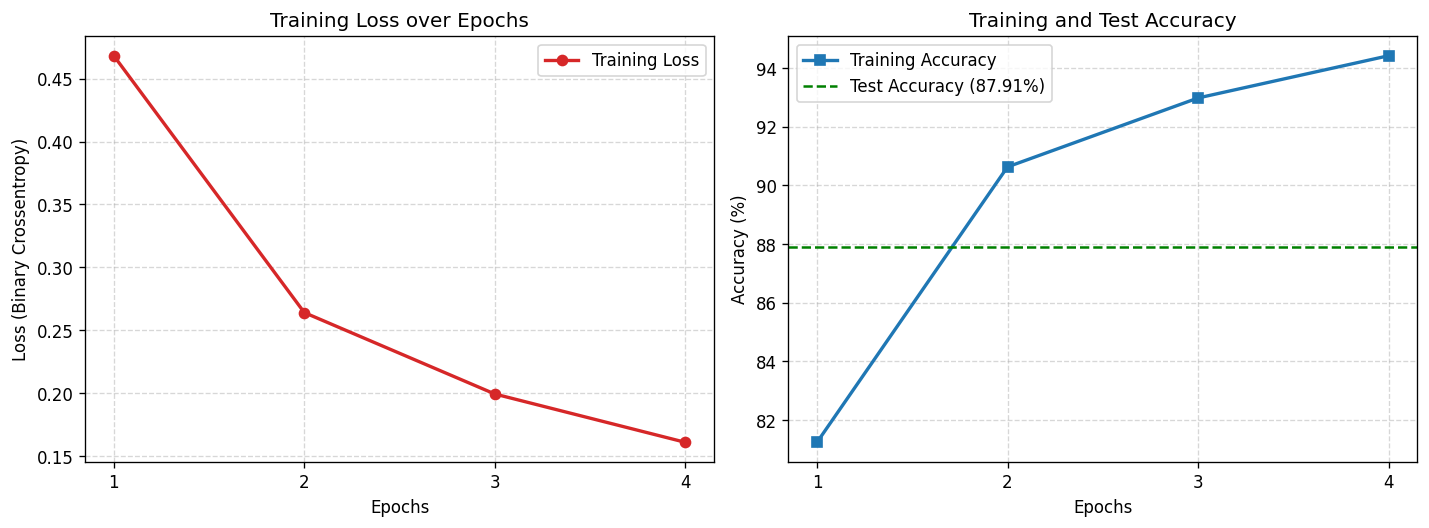

In [9]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 4.5))

# Plot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['loss'], 'o-', color='#d62728', linewidth=2, label='Training Loss')
plt.title('Training Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Binary Crossentropy)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Plot 2: Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, [acc * 100 for acc in history.history['accuracy']], 's-', color='#1f77b4', linewidth=2, label='Training Accuracy')
plt.title('Training Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.savefig('imdb_training_metrics.png', dpi=120)
plt.show()
